# MRI Skull Stripping Pipeline

This notebook skull-strips standardized 3D NIfTI volumes and updates the project manifests.

- Input folder: `D:\Faizaan\1_DATA_PROJECTS\Projects\MutimodelFutureTrends\nifti`
- Output folder: `D:\Faizaan\1_DATA_PROJECTS\Projects\MutimodelFutureTrends\PreporcessedNifiti`
- **Method: HD BET in another environment but saved in the above folders**
- Sanity checks: random slice visualization and histogram mean/std.
- Manifest update: point to skull-stripped paths (overwrites `VolumeNiftiStd` and adds `VolumeNiftiBET`).

In [14]:
# # Cell 1 — Imports and setup
# BASE='/home/faizaan/winshare/1_DATA_PROJECTS/'
# base_url='/home/faizaan/winshare/1_DATA_PROJECTS/Projects/MutimodelFutureTrends/'
#updated to ssd
BASE='/media/faizaan/1C4E3FB04E3F8196/1_DATA_PROJECTS/'
base_url='/media/faizaan/1C4E3FB04E3F8196/1_DATA_PROJECTS/Projects/MutimodelFutureTrends/'
import os
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "2"
import shutil
import nibabel as nib
import numpy as np
from pathlib import Path
from tqdm import tqdm
import torchio as tio
import subprocess
import SimpleITK as sitk

# --- paths ---

input_dir = Path(f"{base_url}/nifti")           # folder containing original .nii.gz images
output_dir = Path(f"{base_url}/ProcessedNifti")
output_dir.mkdir(exist_ok=True)

# --- options ---
process_all = False       # <<< set False to process 3 files only
apply_skull_strip = True  # <<< toggle skull stripping on/off
apply_bias_correct = True
target_size = (128, 128, 128)


#### 1. skulls tripiing

In [2]:
import os
import subprocess
from pathlib import Path
import nibabel as nib
import pandas as pd
from tqdm import tqdm

# ==== CONFIG ====
base_url = Path("/media/faizaan/1C4E3FB04E3F8196/1_DATA_PROJECTS/Projects/MutimodelFutureTrends")
input_dir = base_url / "nifti"
output_dir = base_url / "ProcessedNifti"
output_dir.mkdir(exist_ok=True)

gpu_device = "cuda:0"  # use GPU 2
save_csv = output_dir / "skullstrip_manifest.csv"
max_files = None  # set to small number for testing; change to None for full batch

# ==== HELPER ====
def extract_rid(fname: str):
    """Extract RID (e.g. 002_S_0413_I240812_std -> 0413 or I240812)"""
    parts = fname.split("_")
    rid = None
    for p in parts:
        if p.startswith("I") and p[1:].isdigit():
            rid = p
    return rid or "Unknown"

def skull_strip_image(in_path: Path, out_path: Path):
    """Run HD-BET on a single image"""
    try:
        cmd = [
            "hd-bet",
            "-i", str(in_path),
            "-o", str(out_path),
            "-device", gpu_device,
            "--disable_tta",
        ]
        result = subprocess.run(cmd, capture_output=True, text=True)
        if result.returncode != 0:
            print(f"❌ Failed {in_path.name}: {result.stderr.strip()}")
            return False
        if not out_path.exists():
            print(f"⚠️ Output missing for {in_path.name}")
            return False
        return True
    except Exception as e:
        print(f"❌ Exception on {in_path.name}: {e}")
        return False

# ==== MAIN LOOP ====
records = []
files = sorted([f for f in input_dir.glob("*.nii.gz")])
if max_files:
    files = files[:max_files]

print(f"🧠 Starting HD-BET skull stripping on {len(files)} files...")

for f in tqdm(files):
    out_file = output_dir / f.name  # keep same filename
    success = skull_strip_image(f, out_file)
    if success:
        try:
            img = nib.load(out_file)
            shape = img.shape
            records.append({
                "RID": extract_rid(f.stem),
                "filename": f.name,
                "output_path": str(out_file),
                "shape": shape
            })
        except Exception as e:
            print(f"⚠️ Could not verify {f.name}: {e}")
    else:
        records.append({
            "RID": extract_rid(f.stem),
            "filename": f.name,
            "output_path": None,
            "shape": None
        })

# ==== SAVE MANIFEST ====
df = pd.DataFrame(records)
df.to_csv(save_csv, index=False)
print(f"\n✅ Skull stripping complete. Results saved to {save_csv}")
print(df.head())


🧠 Starting HD-BET skull stripping on 3 files...


100%|██████████| 3/3 [00:57<00:00, 19.12s/it]


✅ Skull stripping complete. Results saved to /home/faizaan/winshare/1_DATA_PROJECTS/Projects/MutimodelFutureTrends/ProcessedNifti/skullstrip_manifest.csv
       RID                       filename  \
0  I238627  002_S_0295_I238627_std.nii.gz   
1  I303066  002_S_0295_I303066_std.nii.gz   
2  I240812  002_S_0413_I240812_std.nii.gz   

                                         output_path            shape  
0  /home/faizaan/winshare/1_DATA_PROJECTS/Project...  (128, 128, 128)  
1  /home/faizaan/winshare/1_DATA_PROJECTS/Project...  (128, 128, 128)  
2  /home/faizaan/winshare/1_DATA_PROJECTS/Project...  (128, 128, 128)  


#### 2.bias correction

In [33]:
import ants
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm import tqdm

# ==== CONFIG ====
base_url = Path("/media/faizaan/1C4E3FB04E3F8196/1_DATA_PROJECTS/Projects/MutimodelFutureTrends")
input_dir = base_url / "ProcessedNifti"              # skull-stripped inputs
output_dir = base_url / "ProcessedNifti_BiasCorr"    # output (will overwrite)
output_dir.mkdir(exist_ok=True)

save_csv = output_dir / "final_preprocessed_manifest.csv"
mni = ants.image_read(ants.get_ants_data("mni"))     # MNI152 1 mm template

target_shape = (128, 128, 128)
apply_zscore_norm = True
max_files = None

# ==== HELPERS ====
def masked_zscore_normalization(arr, mask_threshold=5):
    mask = arr > np.percentile(arr, mask_threshold)
    if np.sum(mask) < 10:
        return arr
    mean = arr[mask].mean()
    std = arr[mask].std() + 1e-6
    return (arr - mean) / std

# ==== MAIN PIPELINE ====
def preprocess_and_register(in_file, out_file, do_norm=True):
    try:
        # --- Step 1: N4 bias correction ---
        img = ants.image_read(str(in_file))
        corrected = ants.n4_bias_field_correction(img)

        # --- Step 2: Affine registration to MNI ---
        reg = ants.registration(
            fixed=mni,
            moving=corrected,
            type_of_transform="Affine",
            aff_metric="mattes"
        )
        reg_img = reg.get("warpedmovout", None)
        if reg_img is None:
            print(f"⚠️ Registration returned None for {in_file.name}, using bias-corrected image for resampling")
            reg_img = corrected

        # --- Step 3: Resample to fixed cube (128³ voxels) ---
        resized = ants.resample_image(
            image=reg_img,
            resample_params=target_shape,
            use_voxels=True,      # interpret params as voxel grid
            interp_type=1          # linear interpolation
        )

        # --- Step 4: Normalize intensity (brain-only) and ensure float32 ---
        arr = resized.numpy().astype(np.float32)
        if do_norm:
            arr = masked_zscore_normalization(arr, mask_threshold=5)
        resized = ants.from_numpy(
            arr,
            spacing=resized.spacing,
            origin=resized.origin,
            direction=resized.direction
        )

        # --- Step 5: Save (overwrite if exists) ---
        ants.image_write(resized, str(out_file))

        # Verify saved shape
        verify_shape = ants.image_read(str(out_file)).numpy().shape
        if tuple(verify_shape) != tuple(target_shape):
            print(f"⚠️ Shape mismatch for {in_file.name}: got {verify_shape}, expected {target_shape}")

        return {
            "filename": in_file.name,
            "path": str(out_file),
            "shape": tuple(verify_shape),
            "mean": float(arr.mean()),
            "std": float(arr.std()),
            "min": float(arr.min()),
            "max": float(arr.max())
        }

    except Exception as e:
        print(f"❌ Failed {in_file.name}: {e}")
        return {"filename": in_file.name, "path": str(out_file), "shape": None}

# ==== MAIN LOOP ====
files = sorted(list(input_dir.glob("*.nii.gz")))
if max_files:
    files = files[:max_files]

print(f"🧠 Running bias correction → registration → 128³ resampling on {len(files)} images...")

records = []
for f in tqdm(files):
    out_file = output_dir / f.name
    rec = preprocess_and_register(f, out_file, do_norm=apply_zscore_norm)
    records.append(rec)

df = pd.DataFrame(records)
df.to_csv(save_csv, index=False)
print(f"\n✅ Completed preprocessing. All outputs are 128×128×128 and saved in {output_dir}")
print(df.head())


🧠 Running bias correction → registration → 128³ resampling on 3 images...


100%|██████████| 3/3 [00:29<00:00,  9.92s/it]

🧠 Running bias correction → registration → 128³ resampling on 3 images...


100%|██████████| 3/3 [00:29<00:00,  9.92s/it]


✅ Completed preprocessing. All outputs are 128×128×128 and saved in /home/faizaan/winshare/1_DATA_PROJECTS/Projects/MutimodelFutureTrends/ProcessedNifti_BiasCorr
                        filename  \
0  002_S_0295_I238627_std.nii.gz   
1  002_S_0295_I303066_std.nii.gz   
2  002_S_0413_I240812_std.nii.gz   

                                                path            shape  \
0  /home/faizaan/winshare/1_DATA_PROJECTS/Project...  (128, 128, 128)   
1  /home/faizaan/winshare/1_DATA_PROJECTS/Project...  (128, 128, 128)   
2  /home/faizaan/winshare/1_DATA_PROJECTS/Project...  (128, 128, 128)   

       mean       std       min       max  
0 -1.462546  1.016744 -2.719318  3.390729  
1 -1.421066  0.999231 -2.546700  3.096030  
2 -1.586486  1.099306 -2.842259  3.755907  


### Sanity Check: Preprocessed NIfTI Files

Verify preprocessed files in `PreprocessedNifti/` folder:
- ✅ Skull stripping effectiveness
- ✅ N4 bias correction applied
- ✅ Resize to 128³ voxels
- ✅ Denoising applied
- ✅ File format (.nii.gz)
- ✅ Intensity distribution (mean ~0, std ~1 for brain voxels)
- ✅ No NaN/Inf values

Loaded 3 images for QC


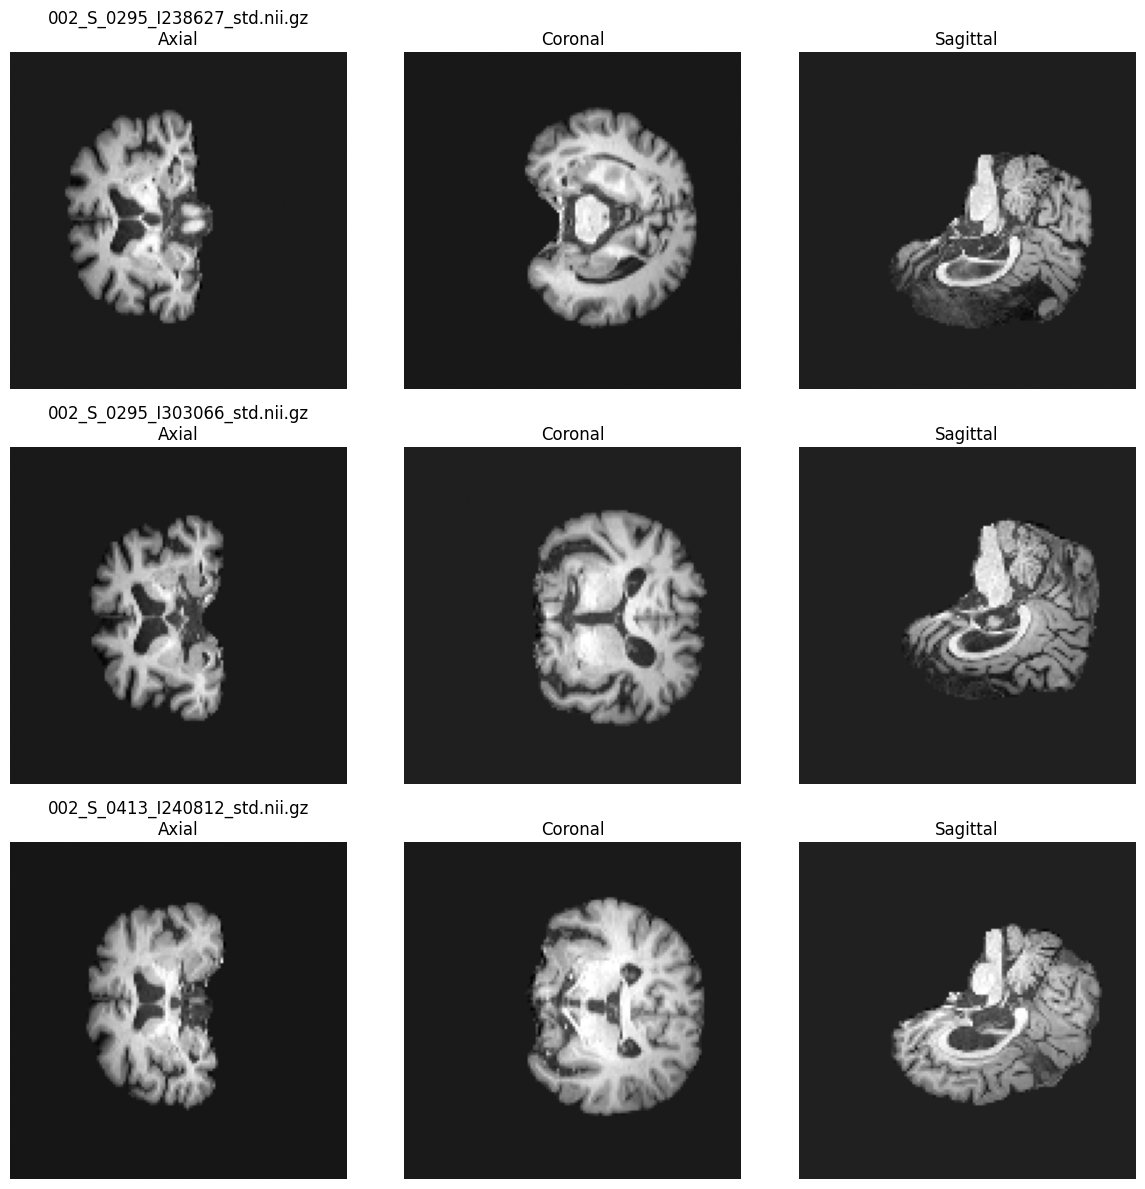


Intensity Statistics Summary:


,filename,shape,min,max,mean,std,median
0,002_S_0295_I238627_std.nii.gz,"(128, 128, 128)",-0.559734,3.425442,0.172217,0.568587,0.0
1,002_S_0295_I303066_std.nii.gz,"(128, 128, 128)",-0.528607,3.503436,0.176455,0.581678,0.0
2,002_S_0413_I240812_std.nii.gz,"(128, 128, 128)",-0.521277,3.552739,0.188967,0.621302,0.0


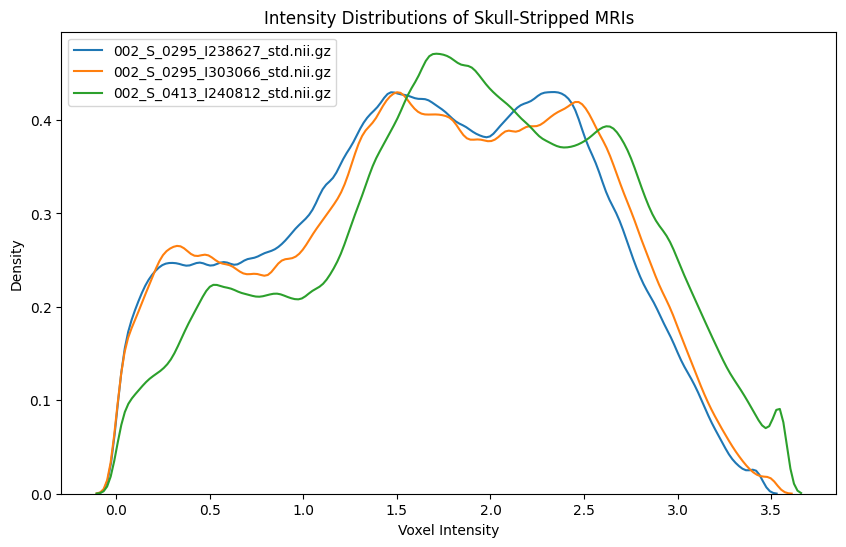

In [4]:
import nibabel as nib
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd
from pathlib import Path
from tqdm import tqdm
import random

# ==== PATHS ====

proc_dir = Path(base_url) / "ProcessedNifti"   # skull-stripped data folder
nii_files = sorted(proc_dir.glob("*.nii.gz"))
print(proc_dir)
print(f"🧠 Found {len(nii_files)} skull-stripped MRI volumes")

if len(nii_files) == 0:
    raise FileNotFoundError(f"No NIfTI files found in {proc_dir}")

# ==== HELPERS ====
def safe_load_image(fp):
    """Load NIfTI image safely and return numpy array"""
    try:
        img = nib.load(fp)
        data = img.get_fdata().astype(np.float32)
        return np.nan_to_num(data)
    except Exception as e:
        print(f"⚠️ Skipping {fp.name}: {e}")
        return None

def get_slices(volume):
    """Return central axial, coronal, sagittal slices"""
    d, h, w = volume.shape
    return volume[d//2, :, :], volume[:, h//2, :], volume[:, :, w//2]

# ==== 1️⃣ COLLECT INTENSITY STATS ====
records = []
for f in tqdm(nii_files, desc="Computing stats"):
    data = safe_load_image(f)
    if data is None:
        continue
    mask = data > np.percentile(data, 2)  # ignore background
    masked = data[mask]
    if masked.size == 0:
        continue
    records.append({
        "filename": f.name,
        "shape": str(tuple(data.shape)),
        "min": float(masked.min()),
        "max": float(masked.max()),
        "mean": float(masked.mean()),
        "std": float(masked.std()),
        "median": float(np.median(masked))
    })

# ==== 2️⃣ CREATE DATAFRAME & CHECK ====
if len(records) == 0:
    raise RuntimeError("No valid MRI volumes processed. Check your NIfTI paths or data integrity.")

stats_df = pd.DataFrame(records)
print(f"\n✅ Processed {len(stats_df)} valid files out of {len(nii_files)}")
print(stats_df.head())

# Describe only numeric columns
num_summary = stats_df.select_dtypes(include=np.number).describe()
print("\n📊 Numeric summary of all images:")
display(num_summary)

# ==== 3️⃣ VISUAL QC (2 RANDOM FILES) ====
qc_files = random.sample(nii_files, 2) if len(nii_files) > 2 else nii_files
fig, axs = plt.subplots(len(qc_files), 3, figsize=(12, 4*len(qc_files)))
if len(qc_files) == 1:
    axs = np.expand_dims(axs, 0)

for i, f in enumerate(qc_files):
    data = safe_load_image(f)
    if data is None:
        continue
    norm_data = (data - np.min(data)) / (np.max(data) - np.min(data) + 1e-8)
    axial, coronal, sagittal = get_slices(norm_data)
    for j, img in enumerate([axial, coronal, sagittal]):
        axs[i, j].imshow(np.rot90(img), cmap="gray", origin="lower")
        axs[i, j].set_title(f"{f.name}\n{['Axial','Coronal','Sagittal'][j]}")
        axs[i, j].axis("off")

plt.suptitle("Central Slices — Skull-Stripped MRIs", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# ==== 4️⃣ INTENSITY DISTRIBUTIONS ====
plt.figure(figsize=(10, 6))
subset = random.sample(nii_files, min(100, len(nii_files)))  # limit to 100

for f in tqdm(subset, desc="Plotting intensity distributions"):
    data = safe_load_image(f)
    if data is None:
        continue
    vox = data[data > np.percentile(data, 2)]
    sns.kdeplot(vox, lw=0.8, label=f.name)

plt.title("Intensity Distributions — Skull-Stripped MRIs")
plt.xlabel("Voxel Intensity")
plt.ylabel("Density")
plt.legend(fontsize=6, loc='upper right', ncol=2)
plt.tight_layout()
plt.show()

# ==== 5️⃣ SAVE SUMMARY ====
save_csv = proc_dir / "skullstripped_intensity_summary.csv"
stats_df.to_csv(save_csv, index=False)
print(f"\n💾 Saved summary CSV: {save_csv}")


#### Demographics of bias corrected final folder vs just skull stripped

Comparison for 3 images, not needed anymore

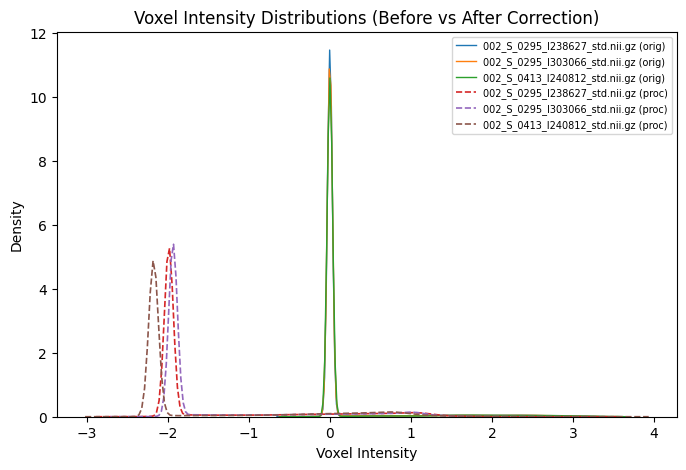

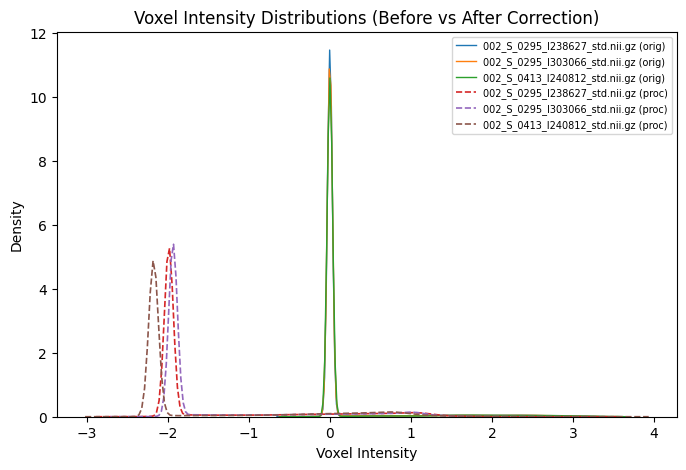

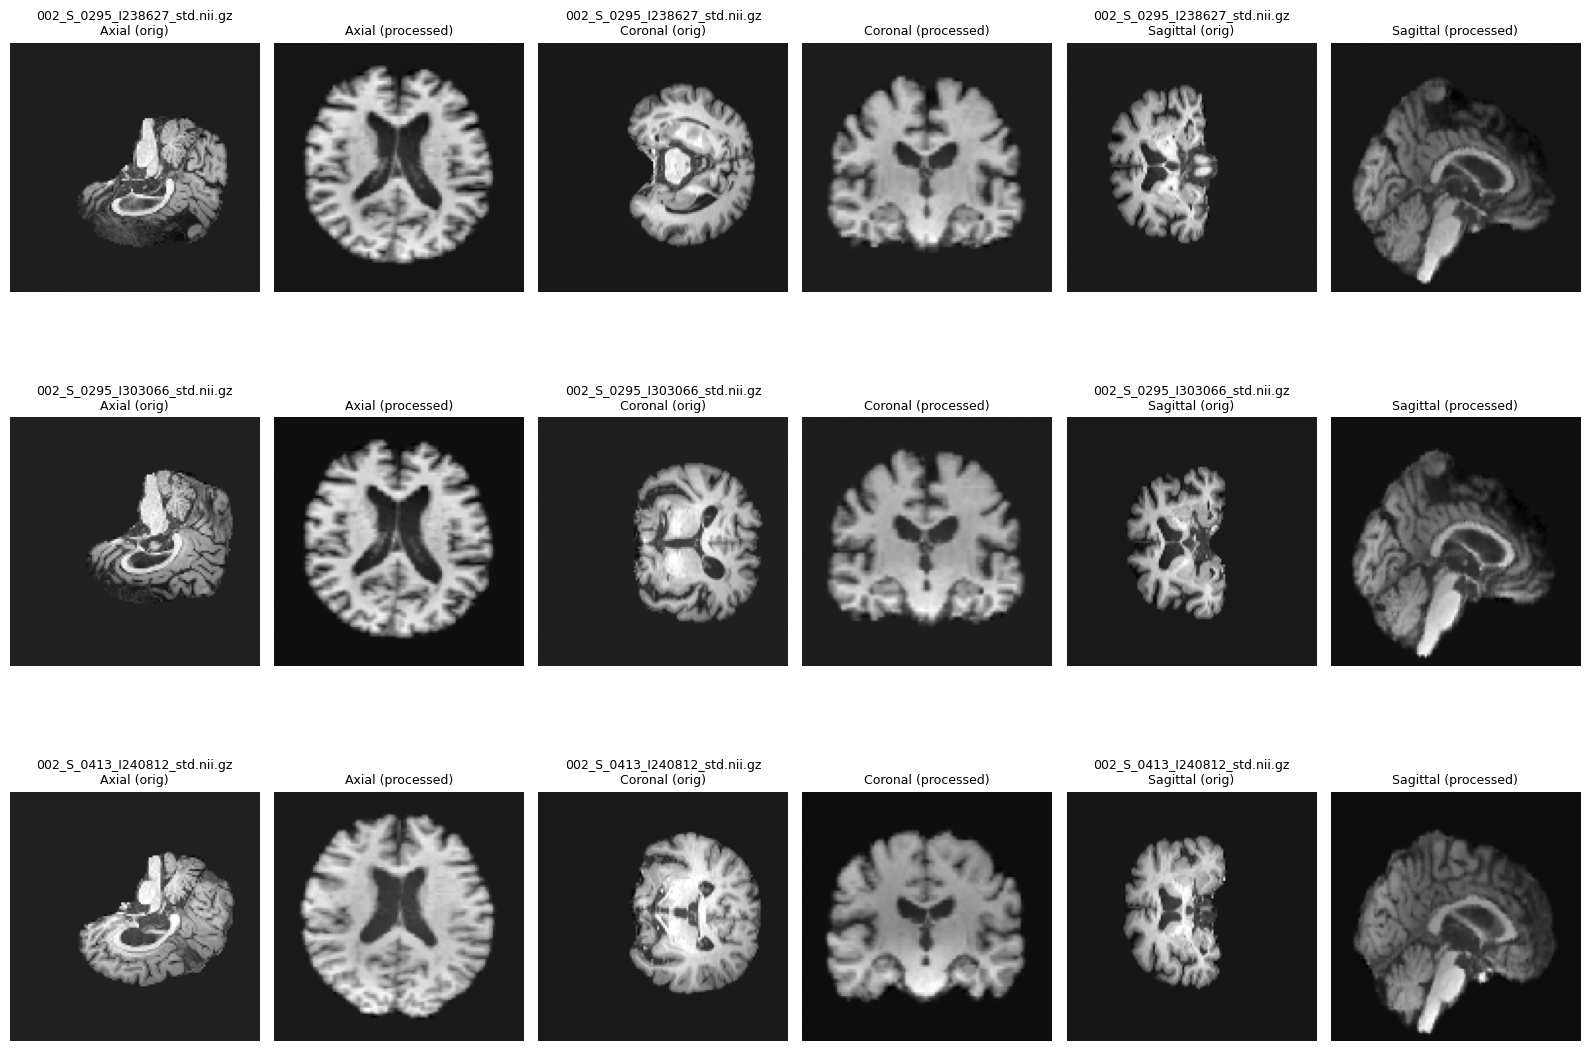

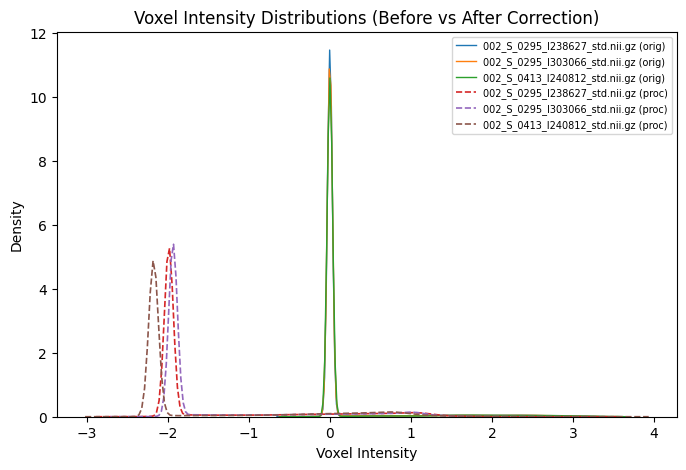

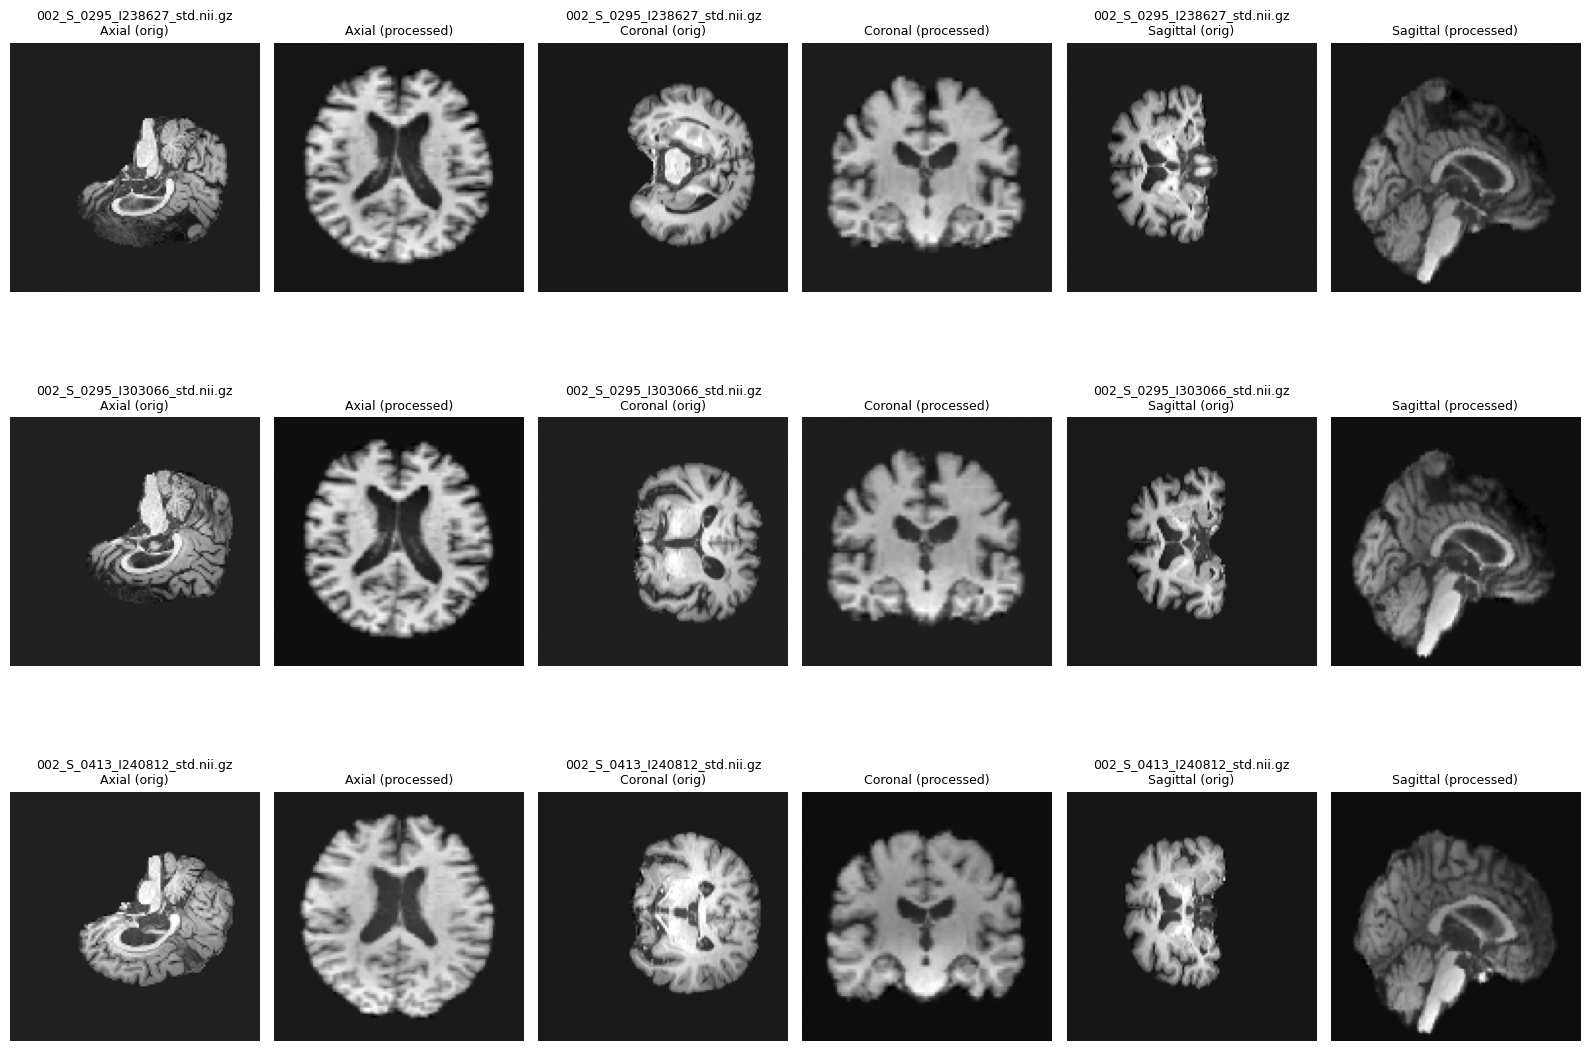

🧠 Intensity summary before vs after correction:



,filename,orig_mean,orig_std,orig_min,orig_max,proc_mean,proc_std,proc_min,proc_max
0,002_S_0295_I238627_std.nii.gz,0.172217,0.568587,-0.559734,3.425442,-1.462547,1.016744,-2.719318,3.390729
1,002_S_0295_I303066_std.nii.gz,0.176455,0.581678,-0.528607,3.503436,-1.421067,0.999231,-2.546700,3.096030
2,002_S_0413_I240812_std.nii.gz,0.188967,0.621302,-0.521277,3.552739,-1.586486,1.099306,-2.842259,3.755907


In [35]:
import nibabel as nib
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd
from pathlib import Path
from tqdm import tqdm
import random

# ==== PATHS ====
proc_dir = Path(base_url) / "ProcessedNifti_BiasCorr"  # bias-corrected data folder
nii_files = sorted(proc_dir.glob("*.nii.gz"))
print(f"📂 Using folder: {proc_dir}")
print(f"🧠 Found {len(nii_files)} bias-corrected MRI volumes")

if len(nii_files) == 0:
    raise FileNotFoundError(f"No NIfTI files found in {proc_dir}")

# ==== HELPERS ====
def safe_load_image(fp):
    """Load NIfTI image safely and return numpy array"""
    try:
        img = nib.load(fp)
        data = img.get_fdata().astype(np.float32)
        return np.nan_to_num(data)
    except Exception:
        return None

def get_slices(volume):
    """Return central axial, coronal, sagittal slices"""
    d, h, w = volume.shape
    return volume[d//2, :, :], volume[:, h//2, :], volume[:, :, w//2]

# ==== 1️⃣ COLLECT INTENSITY STATS ====
records = []
for f in tqdm(nii_files, desc="Computing intensity stats"):
    data = safe_load_image(f)
    if data is None:
        continue
    mask = data > np.percentile(data, 2)  # ignore background
    masked = data[mask]
    if masked.size == 0:
        continue
    records.append({
        "filename": f.name,
        "shape": str(tuple(data.shape)),
        "min": float(masked.min()),
        "max": float(masked.max()),
        "mean": float(masked.mean()),
        "std": float(masked.std()),
        "median": float(np.median(masked))
    })

# ==== 2️⃣ CREATE DATAFRAME & SUMMARY ====
if len(records) == 0:
    raise RuntimeError("No valid MRI volumes processed. Check data integrity.")

stats_df = pd.DataFrame(records)
print(f"\n✅ Processed {len(stats_df)} valid files out of {len(nii_files)}")

num_summary = stats_df.select_dtypes(include=np.number).describe()
print("\n📊 Numeric summary of all bias-corrected MRIs:")
display(num_summary)

# ==== 3️⃣ VISUAL QC (2 RANDOM FILES) ====
qc_files = random.sample(nii_files, 2) if len(nii_files) > 2 else nii_files
fig, axs = plt.subplots(len(qc_files), 3, figsize=(12, 4*len(qc_files)))
if len(qc_files) == 1:
    axs = np.expand_dims(axs, 0)

for i, f in enumerate(qc_files):
    data = safe_load_image(f)
    if data is None:
        continue
    norm_data = (data - np.min(data)) / (np.max(data) - np.min(data) + 1e-8)
    axial, coronal, sagittal = get_slices(norm_data)
    for j, img in enumerate([axial, coronal, sagittal]):
        axs[i, j].imshow(np.rot90(img), cmap="gray", origin="lower")
        axs[i, j].set_title(['Axial', 'Coronal', 'Sagittal'][j])
        axs[i, j].axis("off")

plt.suptitle("Central Slices — Bias-Corrected MRIs", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# ==== 4️⃣ INTENSITY DISTRIBUTIONS (NO LEGENDS, NO FILENAMES) ====
plt.figure(figsize=(10, 6))
subset = random.sample(nii_files, min(100, len(nii_files)))  # limit to 100 for speed

for f in tqdm(subset, desc="Plotting intensity distributions"):
    data = safe_load_image(f)
    if data is None:
        continue
    vox = data[data > np.percentile(data, 2)]
    sns.kdeplot(vox, lw=0.8, alpha=0.4)

plt.title("Intensity Distributions — Bias-Corrected MRIs")
plt.xlabel("Voxel Intensity")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

# ==== 5️⃣ SAVE SUMMARY ====
save_csv = proc_dir / "bias_corrected_intensity_summary.csv"
stats_df.to_csv(save_csv, index=False)
print(f"\n💾 Saved summary CSV: {save_csv}")



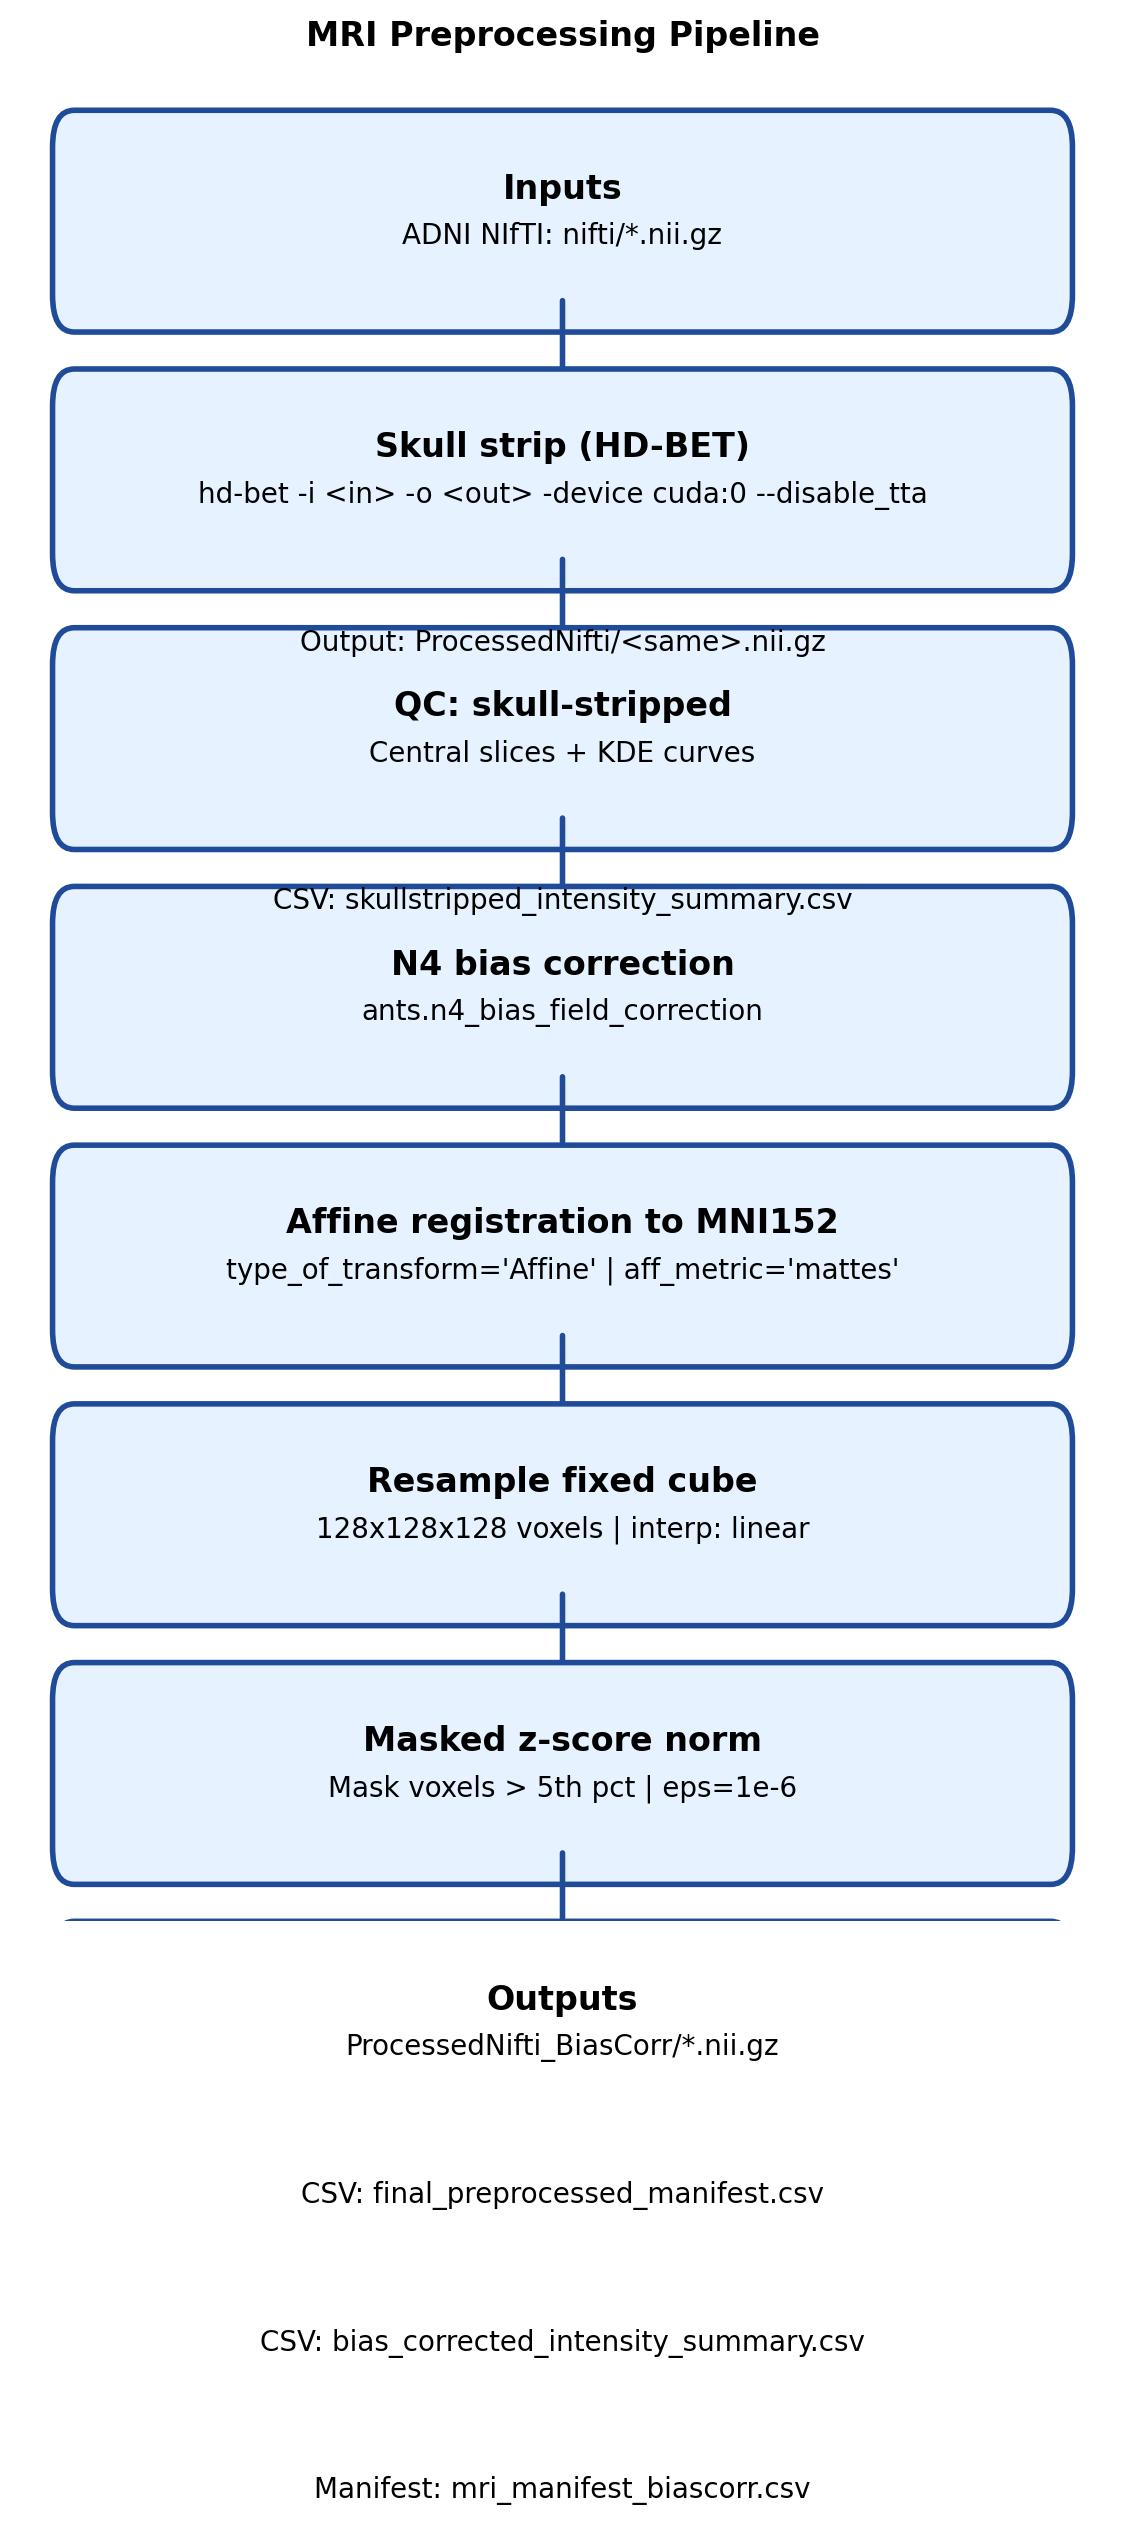

Saved pipeline diagram to preprocessing_pipeline.jpg


In [12]:
from pathlib import Path
from IPython.display import Image, display
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

steps = [
    ("Inputs", ["ADNI NIfTI: nifti/*.nii.gz"]),
    ("Skull strip (HD-BET)", ["hd-bet -i <in> -o <out> -device cuda:0 --disable_tta", "Output: ProcessedNifti/<same>.nii.gz"]),
    ("QC: skull-stripped", ["Central slices + KDE curves", "CSV: skullstripped_intensity_summary.csv"]),
    ("N4 bias correction", ["ants.n4_bias_field_correction"]),
    ("Affine registration to MNI152", ["type_of_transform='Affine' | aff_metric='mattes'"]),
    ("Resample fixed cube", ["128x128x128 voxels | interp: linear"]),
    ("Masked z-score norm", ["Mask voxels > 5th pct | eps=1e-6"]),
    ("Outputs", ["ProcessedNifti_BiasCorr/*.nii.gz", "CSV: final_preprocessed_manifest.csv", "CSV: bias_corrected_intensity_summary.csv", "Manifest: mri_manifest_biascorr.csv"]),
]

fig, ax = plt.subplots(figsize=(7, 12))
ax.axis('off')

x = 0.5
start_y = 0.92
box_w = 0.9
box_h = 0.08
gap = 0.06

for idx, (title, lines) in enumerate(steps):
    cy = start_y - idx * (box_h + gap)
    ax.add_patch(FancyBboxPatch((x - box_w / 2, cy - box_h / 2), box_w, box_h,
                                boxstyle='round,pad=0.02', linewidth=2, edgecolor='#1f4b99', facecolor='#e6f2ff'))
    ax.text(x, cy + box_h * 0.22, title, ha='center', va='center', fontsize=12, fontweight='bold')
    for j, line in enumerate(lines):
        ax.text(x, cy - box_h * 0.1 - j * 0.08, line, ha='center', va='center', fontsize=10)
    if idx < len(steps) - 1:
        next_cy = start_y - (idx + 1) * (box_h + gap)
        arrow = FancyArrowPatch((x, cy - box_h / 2), (x, next_cy + box_h / 2),
                                arrowstyle='->', mutation_scale=12, linewidth=2, color='#1f4b99')
        ax.add_patch(arrow)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_title('MRI Preprocessing Pipeline', fontsize=12, weight='bold', pad=10)

jpg_path = Path('preprocessing_pipeline.jpg')
plt.savefig(jpg_path, dpi=200, bbox_inches='tight')
plt.close(fig)

display(Image(filename=str(jpg_path)))
print(f'Saved pipeline diagram to {jpg_path}')


### updating manifest

check paths later 

In [ ]:
# import pandas as pd
# from pathlib import Path

# # ==== CONFIG ====
# BASE = Path("/media/faizaan/1C4E3FB04E3F8196/1_DATA_PROJECTS/")
# base_url = BASE / "Projects/MutimodelFutureTrends/"
# MANIFEST_DIR = base_url / "manifests"
# BIASCORR_DIR = base_url / "ProcessedNifti_BiasCorr"  # final preprocessed MRIs

# # ==== Locate manifest ====
# manifest_path = MANIFEST_DIR / "mri_manifest.csv"
# if not manifest_path.exists():
#     raise FileNotFoundError(f"Manifest not found: {manifest_path}")

# print(f"📄 Found manifest: {manifest_path}")
# man = pd.read_csv(manifest_path)
# print(f"Loaded manifest with {len(man)} rows")

# # ==== Identify the folder path column ====
# if "SeriesPath" not in man.columns:
#     raise ValueError("Manifest must contain 'SeriesPath' column (ADNI folder path).")

# # ==== Generate new bias-corrected file paths ====
# biascorr_paths = []
# for _, row in man.iterrows():
#     try:
#         # Example folder: .../002_S_0295/MPRAGE/.../I238627
#         folder = Path(row["SeriesPath"])
#         if not folder.exists():
#             biascorr_paths.append("")
#             continue

#         # Extract subject + image ID from path
#         subject = row.get("Subject", "")
#         image_id = row.get("ImageID", "")
#         if not subject or not image_id:
#             biascorr_paths.append("")
#             continue

#         # Construct expected bias-corrected filename (ADNI convention)
#         fname = f"{subject}_{image_id}_std.nii.gz"
#         out_path = (BIASCORR_DIR / fname).resolve()

#         biascorr_paths.append(str(out_path) if out_path.exists() else "")
#     except Exception:
#         biascorr_paths.append("")

# man["VolumeNiftiBiasCorr"] = biascorr_paths
# man["VolumeNiftiStd"] = man["VolumeNiftiBiasCorr"]  # downstream compatibility

# # ==== Save updated manifest ====
# updated_path = manifest_path.with_name("mri_manifest_biascorr.csv")
# man.to_csv(updated_path, index=False)

# found = (man["VolumeNiftiBiasCorr"].astype(str).str.len() > 0).sum()
# print(f"\n✅ Updated manifest saved: {updated_path}")
# print(f"Bias-corrected paths found for {found} / {len(man)} entries")




📄 Found manifest: /media/faizaan/1C4E3FB04E3F8196/1_DATA_PROJECTS/Projects/MutimodelFutureTrends/manifests/mri_manifest.csv
Loaded manifest with 3655 rows

✅ Updated manifest saved: /media/faizaan/1C4E3FB04E3F8196/1_DATA_PROJECTS/Projects/MutimodelFutureTrends/manifests/mri_manifest_biascorr.csv
Bias-corrected paths found for 0 / 3655 entries


#### plotting original , stripped, and bias corrected,

In [29]:
import nibabel as nib
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

# =========================================================
# PATHS
# =========================================================
fname = "051_S_4929_I335399_std.nii.gz"

base = Path("/media/faizaan/1C4E3FB04E3F8196/1_DATA_PROJECTS/Projects/MutimodelFutureTrends")

paths = {
    "Original": base / "nifti" / fname,
    "Skull-Stripped": base / "ProcessedNifti" / fname,
    "Bias Corrected": base / "ProcessedNifti_BiasCorr" / fname,
}

# =========================================================
# HELPERS
# =========================================================
def load_norm(p):
    img = nib.load(str(p))
    data = img.get_fdata().astype(np.float32)
    data = np.nan_to_num(data)
    return (data - data.min()) / (data.max() - data.min() + 1e-8)

def get_slices(vol):
    """Correct central slices: axial=Z, coronal=Y, sagittal=X"""
    x, y, z = vol.shape
    axial    = vol[:, :, z//2]      # XY plane
    coronal  = vol[:, y//2, :]      # XZ plane
    sagittal = vol[x//2, :, :]      # YZ plane
    return axial, coronal, sagittal

# =========================================================
# FUNCTION TO PLOT ONE FIGURE (AX–CO–SA)
# =========================================================
def plot_three_views(title, path, dpi=600):
    vol = load_norm(path)
    axial, coronal, sagittal = get_slices(vol)

    fig, axs = plt.subplots(1, 3, figsize=(12, 4), dpi=dpi)

    views = [axial, coronal, sagittal]
    names = ["Axial", "Coronal", "Sagittal"]

    for i, img in enumerate(views):
        axs[i].imshow(np.rot90(img), cmap="gray")   # kept rotation for display
        axs[i].set_title(f"{title} — {names[i]}", fontsize=12)
        axs[i].axis("off")

    plt.tight_layout()
    plt.show()

# =========================================================
# GENERATE ALL 3 PLOTS
# =========================================================
plot_three_views("Original NIfTI", paths["Original"], dpi=1200)
plot_three_views("Skull-Stripped", paths["Skull-Stripped"], dpi=1200)
plot_three_views("Bias Corrected", paths["Bias Corrected"], dpi=1200)


### Extra graphs and values

In [1]:
# ============================================================
# NeuroSurv-AD (Scrum Day 1) — QC tables + plots across stages
# Stages:
#   1) Original NIfTI
#   2) Skull-stripped (HD-BET output)
#   3) Bias-corrected (N4 output)
#
# Produces:
#   - Per-image metrics table (shape, spacing, intensity stats, brain mask stats)
#   - Paired-difference table (Orig->Skull, Skull->Bias)
#   - Plots:
#       * 3x3 slice grid (same subject across stages)
#       * Histograms (intensity distributions)
#       * Summary barplots (mean/std, nonzero fraction)
#
# Notes:
#   - Assumes same filenames exist in all three folders.
#   - Uses the first 3 matching .nii or .nii.gz files from original folder.
# ============================================================

import os
from pathlib import Path
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt

# -----------------------------
# Paths (edit if needed)
# -----------------------------
BASE = Path("/media/faizaan/1C4E3FB04E3F8196/1_DATA_PROJECTS/")
base_url = BASE / "Projects/MutimodelFutureTrends"

orig_dir = base_url / "nifti"                    # original .nii/.nii.gz
skull_dir = base_url / "ProcessedNifti"          # skull-stripped
bias_dir  = base_url / "ProcessedNifti_BiasCorr" # bias-corrected

out_dir = base_url / "qc_day1_outputs"
out_dir.mkdir(parents=True, exist_ok=True)

# Optional GPU env (not needed for this QC script)
os.environ["CUDA_VISIBLE_DEVICES"] = "2"

# -----------------------------
# Helpers
# -----------------------------
def list_niis(folder: Path):
    return sorted(list(folder.glob("*.nii")) + list(folder.glob("*.nii.gz")))

def robust_stats(x: np.ndarray):
    # x expected 1D, finite values
    if x.size == 0:
        return dict(p01=np.nan, p50=np.nan, p99=np.nan, iqr=np.nan)
    p01, p50, p99 = np.percentile(x, [1, 50, 99])
    q25, q75 = np.percentile(x, [25, 75])
    return dict(p01=float(p01), p50=float(p50), p99=float(p99), iqr=float(q75 - q25))

def infer_foreground_mask(vol: np.ndarray):
    # Simple, explainable: foreground = vol > 0
    # Works well for skull-stripped and many MRI pipelines where background is 0.
    return vol > 0

def load_nifti(path: Path):
    img = nib.load(str(path))
    data = img.get_fdata(dtype=np.float32)
    hdr = img.header
    zooms = hdr.get_zooms()[:3]
    shape = data.shape[:3]
    affine = img.affine
    return data, shape, zooms, affine

def center_slices(vol: np.ndarray):
    # Return mid slices for axial/coronal/sagittal
    z = vol.shape[2] // 2  # axial index
    y = vol.shape[1] // 2  # coronal
    x = vol.shape[0] // 2  # sagittal
    sag = vol[x, :, :]
    cor = vol[:, y, :]
    axi = vol[:, :, z]
    return sag, cor, axi

def normalize_for_display(slice2d: np.ndarray):
    s = slice2d.copy()
    # robust scaling for display
    lo, hi = np.percentile(s[np.isfinite(s)], [1, 99]) if np.isfinite(s).any() else (0, 1)
    if hi <= lo:
        hi = lo + 1e-6
    s = np.clip((s - lo) / (hi - lo), 0, 1)
    return s

# -----------------------------
# Select 3 filenames (same across folders)
# -----------------------------
orig_files = list_niis(orig_dir)
if len(orig_files) == 0:
    raise FileNotFoundError(f"No NIfTI files found in: {orig_dir}")

# pick first 3 by name
selected = orig_files[:3]
selected_names = [p.name for p in selected]

# verify existence in other stages
missing = []
for name in selected_names:
    if not (skull_dir / name).exists():
        missing.append(("skull_stripped_missing", name))
    if not (bias_dir / name).exists():
        missing.append(("bias_corrected_missing", name))

if missing:
    print("WARNING: Some stage files are missing. Metrics will skip missing entries:")
    for tag, name in missing:
        print(f"  - {tag}: {name}")

# -----------------------------
# Compute per-image metrics (meaningful for understanding pipeline effects)
# -----------------------------
rows = []

def compute_metrics(stage: str, path: Path):
    vol, shape, zooms, _ = load_nifti(path)
    finite = vol[np.isfinite(vol)]
    fg_mask = infer_foreground_mask(vol)
    fg = vol[fg_mask & np.isfinite(vol)]

    # basic intensity stats
    mean_all = float(np.mean(finite)) if finite.size else np.nan
    std_all  = float(np.std(finite))  if finite.size else np.nan

    # foreground-focused stats (more meaningful for skull-stripped/bias-corrected)
    mean_fg = float(np.mean(fg)) if fg.size else np.nan
    std_fg  = float(np.std(fg))  if fg.size else np.nan

    rs_all = robust_stats(finite)
    rs_fg  = robust_stats(fg)

    # “brain occupancy” proxy
    fg_frac = float(fg_mask.mean())

    # histogram entropy proxy (distribution complexity) on foreground
    entropy = np.nan
    if fg.size > 100:
        hist, _ = np.histogram(fg, bins=128)
        p = hist.astype(np.float64)
        p = p / (p.sum() + 1e-12)
        p = p[p > 0]
        entropy = float(-(p * np.log(p)).sum())

    # nonzero component for background separation
    nonzero_frac = float((vol != 0).mean())

    return {
        "stage": stage,
        "file": path.name,
        "shape": str(tuple(shape)),
        "spacing_xyz": str(tuple(np.round(zooms, 4))),
        "voxels": int(np.prod(shape)),
        "nonzero_frac": nonzero_frac,
        "fg_frac_gt0": fg_frac,
        "mean_all": mean_all,
        "std_all": std_all,
        "p01_all": rs_all["p01"],
        "median_all": rs_all["p50"],
        "p99_all": rs_all["p99"],
        "iqr_all": rs_all["iqr"],
        "mean_fg": mean_fg,
        "std_fg": std_fg,
        "p01_fg": rs_fg["p01"],
        "median_fg": rs_fg["p50"],
        "p99_fg": rs_fg["p99"],
        "iqr_fg": rs_fg["iqr"],
        "fg_entropy": entropy,
    }

for name in selected_names:
    paths = {
        "original": orig_dir / name,
        "skull_stripped": skull_dir / name,
        "bias_corrected": bias_dir / name,
    }
    for stage, p in paths.items():
        if p.exists():
            rows.append(compute_metrics(stage, p))

metrics_df = pd.DataFrame(rows).sort_values(["file", "stage"])
metrics_csv = out_dir / "qc_metrics_day1.csv"
metrics_df.to_csv(metrics_csv, index=False)

# -----------------------------
# Paired difference table per file (effect size view)
# -----------------------------
def stage_df(stage):
    return metrics_df[metrics_df["stage"] == stage].set_index("file")

diff_rows = []
orig_m = stage_df("original")
skull_m = stage_df("skull_stripped")
bias_m = stage_df("bias_corrected")

common_files = sorted(set(orig_m.index) & set(skull_m.index) & set(bias_m.index))

for f in common_files:
    d1 = (skull_m.loc[f, ["mean_fg","std_fg","p01_fg","median_fg","p99_fg","fg_entropy","fg_frac_gt0","nonzero_frac"]] -
          orig_m.loc[f,  ["mean_fg","std_fg","p01_fg","median_fg","p99_fg","fg_entropy","fg_frac_gt0","nonzero_frac"]])
    d2 = (bias_m.loc[f, ["mean_fg","std_fg","p01_fg","median_fg","p99_fg","fg_entropy","fg_frac_gt0","nonzero_frac"]] -
          skull_m.loc[f, ["mean_fg","std_fg","p01_fg","median_fg","p99_fg","fg_entropy","fg_frac_gt0","nonzero_frac"]])

    diff_rows.append({
        "file": f,
        "orig_to_skull_mean_fg": float(d1["mean_fg"]),
        "orig_to_skull_std_fg": float(d1["std_fg"]),
        "orig_to_skull_p99_fg": float(d1["p99_fg"]),
        "orig_to_skull_fg_frac": float(d1["fg_frac_gt0"]),
        "orig_to_skull_entropy": float(d1["fg_entropy"]),
        "skull_to_bias_mean_fg": float(d2["mean_fg"]),
        "skull_to_bias_std_fg": float(d2["std_fg"]),
        "skull_to_bias_p99_fg": float(d2["p99_fg"]),
        "skull_to_bias_fg_frac": float(d2["fg_frac_gt0"]),
        "skull_to_bias_entropy": float(d2["fg_entropy"]),
    })

diff_df = pd.DataFrame(diff_rows)
diff_csv = out_dir / "qc_differences_day1.csv"
diff_df.to_csv(diff_csv, index=False)

print(f"Saved metrics table: {metrics_csv}")
print(f"Saved difference table: {diff_csv}")

# -----------------------------
# Plot 1: 3x3 slice grid per file (rows=stages, cols=views)
# -----------------------------
stages = [("original", orig_dir), ("skull_stripped", skull_dir), ("bias_corrected", bias_dir)]
views = ["Sagittal", "Coronal", "Axial"]

for name in selected_names:
    fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(9, 9))
    fig.suptitle(f"QC Slices Across Preprocessing Stages\n{name}", fontsize=12)

    for r, (stage, folder) in enumerate(stages):
        p = folder / name
        if not p.exists():
            for c in range(3):
                axes[r, c].axis("off")
            continue

        vol, *_ = load_nifti(p)
        sag, cor, axi = center_slices(vol)
        for c, slc in enumerate([sag, cor, axi]):
            img = normalize_for_display(slc.T)  # transpose for more standard viewing
            axes[r, c].imshow(img, cmap="gray")
            axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
            if r == 0:
                axes[r, c].set_title(views[c], fontsize=10)
            if c == 0:
                axes[r, c].set_ylabel(stage, fontsize=10)

    plt.tight_layout()
    out_png = out_dir / f"slices_3x3_{name.replace('.nii.gz','').replace('.nii','')}.png"
    plt.savefig(out_png, dpi=200)
    plt.close(fig)

print(f"Saved 3x3 slice grids to: {out_dir}")

# -----------------------------
# Plot 2: Intensity histograms (foreground) across stages for each file
# -----------------------------
for name in selected_names:
    fig = plt.figure(figsize=(8, 5))
    plt.title(f"Foreground Intensity Histograms Across Stages\n{name}", fontsize=11)

    for stage, folder in stages:
        p = folder / name
        if not p.exists():
            continue
        vol, *_ = load_nifti(p)
        fg = vol[infer_foreground_mask(vol) & np.isfinite(vol)]
        if fg.size < 50:
            continue

        # Clip to robust range for comparable histograms
        lo, hi = np.percentile(fg, [1, 99])
        fg_clip = np.clip(fg, lo, hi)

        plt.hist(fg_clip, bins=80, alpha=0.35, density=True, label=stage)

    plt.xlabel("Intensity (robust clipped 1–99%)")
    plt.ylabel("Density")
    plt.legend()
    plt.tight_layout()

    out_png = out_dir / f"hist_fg_{name.replace('.nii.gz','').replace('.nii','')}.png"
    plt.savefig(out_png, dpi=200)
    plt.close(fig)

print(f"Saved histograms to: {out_dir}")

# -----------------------------
# Plot 3: Summary barplots (mean_fg, std_fg, fg_frac) across stages (per file)
# -----------------------------
summary_cols = ["mean_fg", "std_fg", "fg_frac_gt0"]
for name in selected_names:
    sub = metrics_df[metrics_df["file"] == name].copy()
    if sub.empty:
        continue
    sub = sub.set_index("stage").reindex(["original","skull_stripped","bias_corrected"])

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.set_title(f"Stage Summary Metrics\n{name}", fontsize=11)

    x = np.arange(len(sub.index))
    width = 0.25

    ax.bar(x - width, sub["mean_fg"].values, width, label="mean_fg")
    ax.bar(x,         sub["std_fg"].values,  width, label="std_fg")
    ax.bar(x + width, sub["fg_frac_gt0"].values, width, label="fg_frac_gt0")

    ax.set_xticks(x)
    ax.set_xticklabels(sub.index, rotation=0)
    ax.set_ylabel("Value (different scales)")
    ax.legend()
    plt.tight_layout()

    out_png = out_dir / f"summary_bars_{name.replace('.nii.gz','').replace('.nii','')}.png"
    plt.savefig(out_png, dpi=200)
    plt.close(fig)

print(f"Saved summary barplots to: {out_dir}")

# -----------------------------
# Optional: Print a compact console table for quick Scrum slide copy
# -----------------------------
print("\n=== Quick QC Table (selected key metrics) ===")
key_cols = ["file","stage","shape","spacing_xyz","fg_frac_gt0","mean_fg","std_fg","p01_fg","median_fg","p99_fg","fg_entropy"]
print(metrics_df[key_cols].to_string(index=False))


Saved metrics table: /media/faizaan/1C4E3FB04E3F8196/1_DATA_PROJECTS/Projects/MutimodelFutureTrends/qc_day1_outputs/qc_metrics_day1.csv
Saved difference table: /media/faizaan/1C4E3FB04E3F8196/1_DATA_PROJECTS/Projects/MutimodelFutureTrends/qc_day1_outputs/qc_differences_day1.csv
Saved 3x3 slice grids to: /media/faizaan/1C4E3FB04E3F8196/1_DATA_PROJECTS/Projects/MutimodelFutureTrends/qc_day1_outputs
Saved histograms to: /media/faizaan/1C4E3FB04E3F8196/1_DATA_PROJECTS/Projects/MutimodelFutureTrends/qc_day1_outputs
Saved summary barplots to: /media/faizaan/1C4E3FB04E3F8196/1_DATA_PROJECTS/Projects/MutimodelFutureTrends/qc_day1_outputs

=== Quick QC Table (selected key metrics) ===
                         file          stage           shape                                                  spacing_xyz  fg_frac_gt0  mean_fg   std_fg   p01_fg  median_fg   p99_fg  fg_entropy
002_S_0295_I238627_std.nii.gz bias_corrected (128, 128, 128) (np.float32(1.4252), np.float32(1.7087), np.float32(1.4252))